# Diabetes Readmission Prediction
## Logistic Regression Analysis - Sudarshan Tiwari

### Objective
Predict whether a diabetic patient will be readmitted to the hospital **within 30 days** of discharge
using logistic regression, and see how well it can pick out the patients who come back.

To keep my results comparable with the rest of the group, I cleaned the data and split it into
train/validation/test sets the same way as the Random Forest model (same rows, same patient-based
60/20/20 split, same `random_state=42`).

In [1]:
# Imports and load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

df = pd.read_csv('../Data/diabetic_data.csv')
print("Dataset shape:", df.shape)
print("Unique patients:", df['patient_nbr'].nunique())

Dataset shape: (101766, 50)
Unique patients: 71518


## Data Cleaning

### Missing data
The dataset uses `?` for missing values, so I replaced those with `NaN` and counted how much is missing in each column.

In [2]:
# Replace all ? with NaN so pandas recognizes them as missing values
df = df.replace('?', np.nan)

# Treat invalid gender entries as missing
df['gender'] = df['gender'].replace('Unknown/Invalid', np.nan)

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage Missing': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_summary = missing_summary[missing_summary['Missing Values'] > 0]
print(missing_summary.sort_values(by='Percentage Missing', ascending=False))

                   Missing Values  Percentage Missing
weight                      98569               96.86
max_glu_serum               96420               94.75
A1Cresult                   84748               83.28
medical_specialty           49949               49.08
payer_code                  40256               39.56
race                         2273                2.23
diag_3                       1423                1.40
diag_2                        358                0.35
diag_1                         21                0.02
gender                          3                0.00


Here is how I handled each column with missing data:

| Attribute | % missing | What I did |
|---|---|---|
| `weight` | ~97% | Dropped the column. Almost all of it is missing, so there is nothing to fill it in from |
| `payer_code` | ~40% | Dropped. It is billing information and has nothing to do with the patient's health |
| `encounter_id`, `patient_nbr` | 0% | These are IDs, not features. I kept `patient_nbr` aside to split the data by patient |
| `max_glu_serum`, `A1Cresult` | ~95%, ~83% | The file stores `None` here, meaning the test was not done, and pandas reads that as missing. I filled these with **"Not measured"** because whether a patient was tested could itself be useful |
| `medical_specialty`, `race`, `diag_1/2/3` | 0.02%-49% | Filled with **"Unknown"** |
| `gender` | 3 rows | Removed these 3 rows. I remove them after splitting the data so my split stays exactly the same as the Random Forest one |

I also removed patients who died during the visit (discharge codes 11, 19, 20, 21), since they can never be readmitted.

In [3]:
# Drop attributes
df = df.drop(columns=['weight', 'payer_code', 'encounter_id'])

# Fill with a global constant
df[['max_glu_serum', 'A1Cresult']] = df[['max_glu_serum', 'A1Cresult']].fillna('Not measured')
fill_unknown = ['medical_specialty', 'race', 'diag_1', 'diag_2', 'diag_3']
df[fill_unknown] = df[fill_unknown].fillna('Unknown')

# Remove patients who expired (they cannot be readmitted)
df = df[~df['discharge_disposition_id'].isin([11, 19, 20, 21])]

# Target: 1 = readmitted within 30 days, 0 = otherwise
df['readmitted'] = (df['readmitted'] == '<30').astype(int)

print("Remaining missing values (only the 3 invalid gender rows):", df.isnull().sum().sum())
print("Shape after cleaning:", df.shape)
print(df['readmitted'].value_counts(normalize=True).mul(100).round(2))

Remaining missing values (only the 3 invalid gender rows): 3
Shape after cleaning: (100114, 47)
readmitted
0    88.66
1    11.34
Name: proportion, dtype: float64


Only about **11%** of the encounters are readmissions within 30 days, so the data is very imbalanced. A model
that always says "not readmitted" would already be about 89% accurate without finding a single readmission.
Because of this I look at precision, recall, F1 and ROC/AUC, not just accuracy.

## Preparing the Features

### Types of attributes
* **Ordinal** - `age` is given as ranges (`[0-10)`, `[10-20)`, ...). I turned it into 0-9 so the order is kept.
* **Binary** - `change` (Ch/No), `diabetesMed` (Yes/No), `gender` (Male/Female) become 0/1.
* **Nominal** - race, the admission/discharge/source IDs (they are numbers, but just labels), specialty,
  diagnoses, test results and medications. These have no order, so each value gets its own 0/1 column
  (one-hot encoding). Logistic regression multiplies every input by a weight, so giving these categories
  numbers like 1, 2, 3 would make up an order that isn't real.
* **Numeric** - counts such as `time_in_hospital`, `num_medications`, `number_inpatient`.

In [4]:
# Ordinal attribute: age interval -> ordered code 0..9
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)',
             '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']
df['age'] = df['age'].map({a: i for i, a in enumerate(age_order)})

# Remember the 3 invalid-gender rows; they are removed after the split
valid_gender = df['gender'].notna()

# Binary attributes -> 0/1
df['change'] = (df['change'] == 'Ch').astype(int)
df['diabetesMed'] = (df['diabetesMed'] == 'Yes').astype(int)
df['gender'] = (df['gender'] == 'Male').astype(int)

# ID codes are nominal labels, not quantities
for col in ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']:
    df[col] = df[col].astype(str)

### Grouping the diagnosis codes
`diag_1`, `diag_2` and `diag_3` are ICD-9 codes with around 700-800 different values each. One-hot encoding
them directly would create thousands of mostly-empty columns. Instead I grouped each code into its general
disease category (circulatory, respiratory, diabetes, injury, ...), which leaves 9 groups per diagnosis.

In [5]:
def diagnosis_group(code):
    # Generalize an ICD-9 code to its higher-level disease group (concept hierarchy)
    if code == 'Unknown':
        return 'Unknown'
    if code.startswith('V') or code.startswith('E'):
        return 'Other'
    value = float(code)
    if 390 <= value <= 459 or int(value) == 785:
        return 'Circulatory'
    if 460 <= value <= 519 or int(value) == 786:
        return 'Respiratory'
    if 520 <= value <= 579 or int(value) == 787:
        return 'Digestive'
    if int(value) == 250:
        return 'Diabetes'
    if 800 <= value <= 999:
        return 'Injury'
    if 710 <= value <= 739:
        return 'Musculoskeletal'
    if 580 <= value <= 629 or int(value) == 788:
        return 'Genitourinary'
    if 140 <= value <= 239:
        return 'Neoplasms'
    return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df[col] = df[col].apply(diagnosis_group)

df['diag_1'].value_counts()

diag_1
Circulatory        29881
Other              17887
Respiratory        14074
Digestive           9380
Diabetes            8693
Injury              6881
Genitourinary       5054
Musculoskeletal     4944
Neoplasms           3299
Unknown               21
Name: count, dtype: int64

### Removing columns with only one value
`examide` and `citoglipton` are "No" for every single encounter, so they can't help the model (and their
standard deviation of 0 would break scaling).

In [6]:
single_value_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Dropping single-valued attributes:", single_value_cols)
df = df.drop(columns=single_value_cols)

numerical_columns = [
    'age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_outpatient', 'number_emergency',
    'number_inpatient', 'number_diagnoses'
]
binary_columns = ['gender', 'change', 'diabetesMed']
categorical_columns = [c for c in df.columns
                       if c not in numerical_columns + binary_columns + ['readmitted', 'patient_nbr']]

print("Numerical:", len(numerical_columns), "| Binary:", len(binary_columns),
      "| Nominal:", len(categorical_columns))
print(categorical_columns)

Dropping single-valued attributes: ['examide', 'citoglipton']
Numerical: 9 | Binary: 3 | Nominal: 31
['race', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


## Train / Validation / Test Split

I split the data into a training set, a validation set for choosing settings, and a test set that I only
use once at the very end.

Each row is a hospital visit, and many patients have more than one visit. If the same patient showed up in
both training and testing, the test score would look better than it really is. So I split by patient with
`GroupShuffleSplit`, which gives a 60% / 20% / 20% split with no patient in more than one set.

I split the exact same rows, in the same order, with the same `random_state=42` as the Random Forest model,
so both models train and test on the same patients. I only drop the 3 invalid-gender rows after splitting,
because dropping them first would shuffle the patients differently.

In [7]:
X = df.drop(columns=['readmitted', 'patient_nbr'])
y = df['readmitted']
groups = df['patient_nbr']

# First split: 80% train+validation / 20% test
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_val_idx, test_idx = next(splitter.split(X, y, groups))

X_train_val, y_train_val = X.iloc[train_val_idx], y.iloc[train_val_idx]
groups_train_val = groups.iloc[train_val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
groups_test = groups.iloc[test_idx]

# Second split: 25% of train+validation -> validation (overall 60/20/20)
splitter_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, val_idx = next(splitter_val.split(X_train_val, y_train_val, groups_train_val))

X_train, y_train = X_train_val.iloc[train_idx], y_train_val.iloc[train_idx]
X_val, y_val = X_train_val.iloc[val_idx], y_train_val.iloc[val_idx]
groups_train = groups_train_val.iloc[train_idx]
groups_val = groups_train_val.iloc[val_idx]

# Ignore the tuple: drop the 3 invalid-gender rows from whichever set they fell into
def keep_valid(X_part, y_part, g_part):
    mask = valid_gender.loc[X_part.index]
    return X_part[mask], y_part[mask], g_part[mask]

X_train, y_train, groups_train = keep_valid(X_train, y_train, groups_train)
X_val, y_val, groups_val = keep_valid(X_val, y_val, groups_val)
X_test, y_test, groups_test = keep_valid(X_test, y_test, groups_test)
X_train_val, y_train_val, groups_train_val = keep_valid(X_train_val, y_train_val, groups_train_val)

print("Training:  ", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:   ", X_test.shape)

print("\nPatient overlap train/val:", len(set(groups_train) & set(groups_val)))
print("Patient overlap train/test:", len(set(groups_train) & set(groups_test)))
print("Patient overlap val/test:  ", len(set(groups_val) & set(groups_test)))

print("\nPercent readmitted <30 -> train: %.2f  val: %.2f  test: %.2f" %
      (y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100))

Training:   (59964, 43)
Validation: (20073, 43)
Testing:    (20074, 43)

Patient overlap train/val: 0
Patient overlap train/test: 0
Patient overlap val/test:   0

Percent readmitted <30 -> train: 11.22  val: 11.57  test: 11.48


### Encoding and scaling
* Nominal attributes are one-hot encoded. Any value that appears in fewer than 100 training rows (like rare
  specialties or discharge codes) is grouped into one "infrequent" column, because a weight learned from
  only a handful of patients is mostly noise.
* Numeric attributes are z-score normalized: `v' = (v - mean) / std_dev`. Logistic regression is trained with
  gradient descent, which struggles when features are on very different scales (e.g. `num_lab_procedures` goes
  up to ~130 while `number_emergency` is mostly 0). Scaling also makes the weights comparable to each other.
* The encoder and scaler are fit on the **training data only**. A `Pipeline` then applies the same
  transformation to the validation and test data so no information leaks from them.

In [8]:
def make_preprocessor():
    return ColumnTransformer(transformers=[
        ('numerical', StandardScaler(), numerical_columns),
        ('binary', 'passthrough', binary_columns),
        ('categorical', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=100), categorical_columns)
    ])

preprocessor = make_preprocessor().fit(X_train)
print("Number of attributes after encoding:", len(preprocessor.get_feature_names_out()))

Number of attributes after encoding: 170


## How Logistic Regression Works

Logistic regression is basically a single neuron with a **sigmoid** activation:

$$ z = w_0 + w_1 x_1 + \dots + w_n x_n, \qquad f(z) = \frac{1}{1 + e^{-z}} $$

* `f(z)` is always between 0 and 1, so I read it as **P(readmitted within 30 days | x)**.
* The prediction is 1 when `f(z) >= threshold` (0.5 by default).
* The weights are learned with gradient descent. The derivative of the sigmoid is `f(1 - f)`, and with the
  log-loss the gradient for each weight simplifies to `(f(x) - y) x_j`. That gives the update
  `w_j <- w_j + eta * (y - f(x)) * x_j`: each weight moves based on the error, scaled by the learning rate
  `eta`, and this is repeated for a number of **epochs**.

### Writing it from scratch
Before using scikit-learn, I wrote a small NumPy version to make sure I understood exactly what the model
does. Every epoch it updates the weights using the whole training set. Since only ~11% of the training rows
are readmissions, I weighted each class's error by `n / (2 * n_class)` so both classes count equally.

**Learning rate:** a learning rate that is too big makes the updates overshoot. I first tried 0.5 and the
loss kept jumping up and down. With 0.05 the loss went down every epoch, and 1000 epochs was enough for it
to level off (see the plot below).

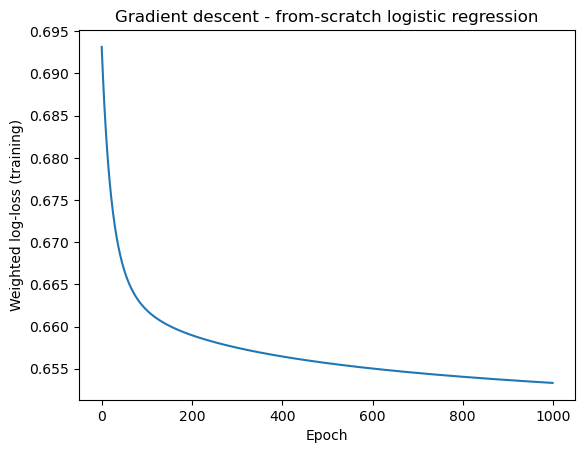

From-scratch model on the VALIDATION set (threshold 0.5)
Accuracy:  0.654
Precision: 0.182
Recall:    0.567
F1:        0.275
AUC:       0.666


In [9]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_logistic_regression(X, y, learning_rate=0.05, epochs=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    # class weights so the minority (readmitted) class is not ignored
    class_weight = np.where(y == 1, n_samples / (2 * y.sum()), n_samples / (2 * (n_samples - y.sum())))
    losses = []
    for epoch in range(epochs):
        f = sigmoid(X @ w + b)                       # forward pass
        error = class_weight * (y - f)               # weighted error (y - f(x))
        w = w + learning_rate * (X.T @ error) / n_samples   # weight update (batch / epoch)
        b = b + learning_rate * error.mean()
        f = np.clip(f, 1e-12, 1 - 1e-12)
        losses.append(-np.mean(class_weight * (y * np.log(f) + (1 - y) * np.log(1 - f))))
    return w, b, losses

X_train_enc = preprocessor.transform(X_train).toarray()
X_val_enc = preprocessor.transform(X_val).toarray()

w, b, losses = train_logistic_regression(X_train_enc, y_train.to_numpy())

plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Weighted log-loss (training)')
plt.title('Gradient descent - from-scratch logistic regression')
plt.show()

scratch_val_prob = sigmoid(X_val_enc @ w + b)
scratch_val_pred = (scratch_val_prob >= 0.5).astype(int)
print("From-scratch model on the VALIDATION set (threshold 0.5)")
print("Accuracy: ", round(accuracy_score(y_val, scratch_val_pred), 3))
print("Precision:", round(precision_score(y_val, scratch_val_pred), 3))
print("Recall:   ", round(recall_score(y_val, scratch_val_pred), 3))
print("F1:       ", round(f1_score(y_val, scratch_val_pred), 3))
print("AUC:      ", round(roc_auc_score(y_val, scratch_val_prob), 3))

### Using scikit-learn's `LogisticRegression`
scikit-learn's `LogisticRegression` is the same model with a faster optimizer. It also has a regularization
setting `C`: a smaller `C` keeps the weights small, which helps prevent overfitting. I used
`class_weight='balanced'`, which does the same class weighting as my version above.

**Tuning `C` on the validation set:** I trained a model for each `C` value and kept the one that did best on
the validation set. Because the data is imbalanced, I picked the best `C` by F1-score instead of accuracy,
and I show AUC next to it.

In [10]:
def make_model(C):
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('classifier', LogisticRegression(C=C, class_weight='balanced', max_iter=1000))
    ])

C_values = [0.001, 0.01, 0.1, 1, 10, 100]
tuning_rows = []
for C in C_values:
    model = make_model(C).fit(X_train, y_train)
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)
    tuning_rows.append({
        'C': C,
        'Accuracy': accuracy_score(y_val, val_pred),
        'Precision': precision_score(y_val, val_pred),
        'Recall': recall_score(y_val, val_pred),
        'F1': f1_score(y_val, val_pred),
        'AUC': roc_auc_score(y_val, val_prob)
    })

tuning_df = pd.DataFrame(tuning_rows)
print(tuning_df.round(4).to_string(index=False))

best_C = tuning_df.loc[tuning_df['F1'].idxmax(), 'C']
print("\nBest C on validation set (by F1):", best_C)

      C  Accuracy  Precision  Recall     F1    AUC
  0.001    0.6575     0.1817  0.5596 0.2744 0.6663
  0.010    0.6654     0.1845  0.5532 0.2768 0.6695
  0.100    0.6674     0.1856  0.5532 0.2780 0.6693
  1.000    0.6668     0.1852  0.5527 0.2774 0.6681
 10.000    0.6674     0.1856  0.5532 0.2779 0.6680
100.000    0.6672     0.1852  0.5519 0.2774 0.6679

Best C on validation set (by F1): 0.1


### Choosing the decision threshold
The model outputs a probability, and 0.5 is not necessarily the best cutoff for imbalanced data. Lowering
the threshold catches more readmissions (higher recall) but also gives more false alarms (lower precision).
I tried several thresholds on the **validation set** and kept the one with the best F1-score.

In [11]:
model = make_model(best_C).fit(X_train, y_train)
val_prob = model.predict_proba(X_val)[:, 1]

threshold_rows = []
for threshold in np.arange(0.30, 0.80, 0.05):
    val_pred = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': round(threshold, 2),
        'Accuracy': accuracy_score(y_val, val_pred),
        'Precision': precision_score(y_val, val_pred),
        'Recall': recall_score(y_val, val_pred),
        'F1': f1_score(y_val, val_pred)
    })

threshold_df = pd.DataFrame(threshold_rows)
print(threshold_df.round(4).to_string(index=False))

best_threshold = threshold_df.loc[threshold_df['F1'].idxmax(), 'Threshold']
print("\nBest threshold on validation set (by F1):", best_threshold)

 Threshold  Accuracy  Precision  Recall     F1
      0.30    0.1848     0.1218  0.9733 0.2165
      0.35    0.2867     0.1309  0.9156 0.2291
      0.40    0.4239     0.1458  0.8188 0.2475
      0.45    0.5614     0.1677  0.7038 0.2708
      0.50    0.6674     0.1856  0.5532 0.2780
      0.55    0.7469     0.2105  0.4318 0.2831
      0.60    0.8037     0.2430  0.3293 0.2797
      0.65    0.8380     0.2742  0.2428 0.2575
      0.70    0.8582     0.3020  0.1718 0.2190
      0.75    0.8721     0.3443  0.1167 0.1743

Best threshold on validation set (by F1): 0.55


## Cross Validation

To make sure my results weren't just from one lucky split, I also ran **5-fold stratified cross validation**
on the training + validation data. Stratified folds keep the same ~11% readmission rate in every fold, which
matters for imbalanced data. I used `StratifiedGroupKFold` so a patient is never in both the training and
testing fold.

In [12]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for scoring in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    scores = cross_val_score(make_model(best_C), X_train_val, y_train_val,
                             groups=groups_train_val, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"{scoring:>9}: {np.round(scores, 3)}  mean = {scores.mean():.3f} (+/- {scores.std():.3f})")

 accuracy: [0.664 0.67  0.677 0.67  0.668]  mean = 0.670 (+/- 0.004)


precision: [0.181 0.182 0.182 0.181 0.182]  mean = 0.181 (+/- 0.000)


   recall: [0.561 0.546 0.537 0.54  0.545]  mean = 0.546 (+/- 0.008)


       f1: [0.274 0.273 0.271 0.271 0.272]  mean = 0.272 (+/- 0.001)


  roc_auc: [0.67  0.664 0.666 0.663 0.661]  mean = 0.665 (+/- 0.003)


## Final Evaluation on the Test Set
For the final model I trained on the training + validation data using the best `C`, then evaluated it once
on the test set using the threshold I picked.

In [13]:
final_model = make_model(best_C).fit(X_train_val, y_train_val)

test_prob = final_model.predict_proba(X_test)[:, 1]
final_predictions = (test_prob >= best_threshold).astype(int)

print(f"C = {best_C}, threshold = {best_threshold}\n")
print("Accuracy: ", round(accuracy_score(y_test, final_predictions), 4))
print("Precision:", round(precision_score(y_test, final_predictions), 4))
print("Recall:   ", round(recall_score(y_test, final_predictions), 4))
print("F1:       ", round(f1_score(y_test, final_predictions), 4))
print("AUC:      ", round(roc_auc_score(y_test, test_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions,
                            target_names=['Not readmitted', 'Readmitted <30']))

# Baseline: always predict the majority class
baseline = np.zeros_like(y_test)
print("Baseline (always 'Not readmitted') accuracy:", round(accuracy_score(y_test, baseline), 4),
      "| recall:", recall_score(y_test, baseline))

C = 0.1, threshold = 0.55

Accuracy:  0.7497
Precision: 0.2071
Recall:    0.4174
F1:        0.2769
AUC:       0.6568

Classification Report:
                precision    recall  f1-score   support

Not readmitted       0.91      0.79      0.85     17769
Readmitted <30       0.21      0.42      0.28      2305

      accuracy                           0.75     20074
     macro avg       0.56      0.61      0.56     20074
  weighted avg       0.83      0.75      0.78     20074

Baseline (always 'Not readmitted') accuracy: 0.8852 | recall: 0.0


### Confusion matrix
Rows are the actual class and columns are the predicted class.

                        Predicted: Readmitted  Predicted: Not readmitted
Actual: Readmitted                        962                       1343
Actual: Not readmitted                   3682                      14087

TP = 962, FN = 1343, FP = 3682, TN = 14087
Precision = TP/(TP+FP) = 0.207
Recall    = TP/(TP+FN) = 0.417


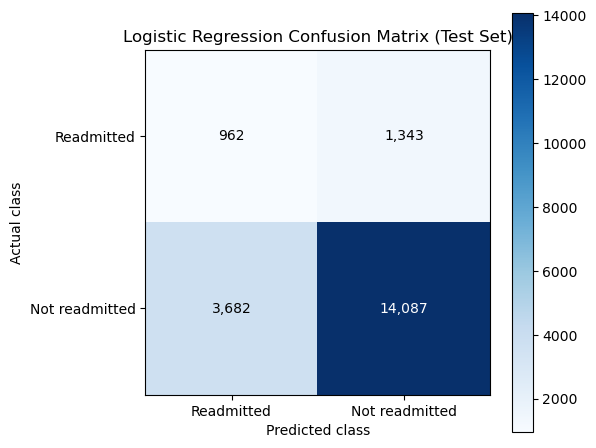

In [14]:
cm = confusion_matrix(y_test, final_predictions, labels=[1, 0])
tp, fn, fp, tn = cm.ravel()
print(pd.DataFrame(cm,
                   index=['Actual: Readmitted', 'Actual: Not readmitted'],
                   columns=['Predicted: Readmitted', 'Predicted: Not readmitted']))
print(f"\nTP = {tp}, FN = {fn}, FP = {fp}, TN = {tn}")
print(f"Precision = TP/(TP+FP) = {tp / (tp + fp):.3f}")
print(f"Recall    = TP/(TP+FN) = {tp / (tp + fn):.3f}")

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xticks([0, 1], ['Readmitted', 'Not readmitted'])
plt.yticks([0, 1], ['Readmitted', 'Not readmitted'])
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title('Logistic Regression Confusion Matrix (Test Set)')
plt.colorbar()
plt.tight_layout()
plt.show()

### ROC curve and AUC
This plots the true positive rate, TP / (TP + FN), against the false positive rate, FP / (FP + TN), for every
possible threshold. The dashed diagonal is random guessing (AUC = 0.5). A perfect model would have AUC = 1.

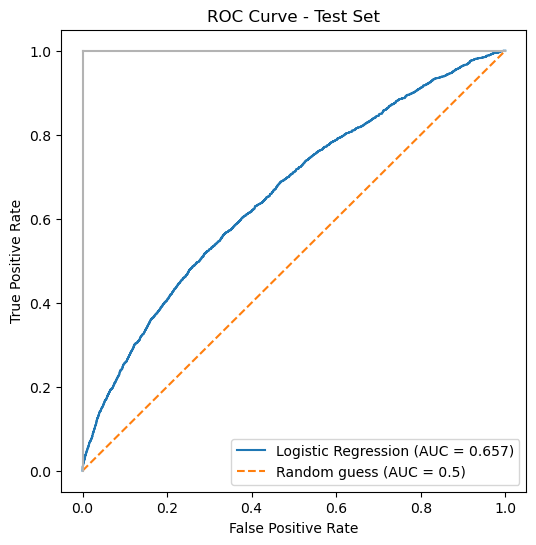

In [15]:
fpr, tpr, thresholds = roc_curve(y_test, test_prob)
auc = roc_auc_score(y_test, test_prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], ls="--", label='Random guess (AUC = 0.5)')   # diagonal line
plt.plot([0, 0], [1, 0], c=".7")                                # left vertical line
plt.plot([1, 1], c=".7")                                        # top horizontal line
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.title('ROC Curve - Test Set')
plt.legend(loc='lower right')
plt.show()

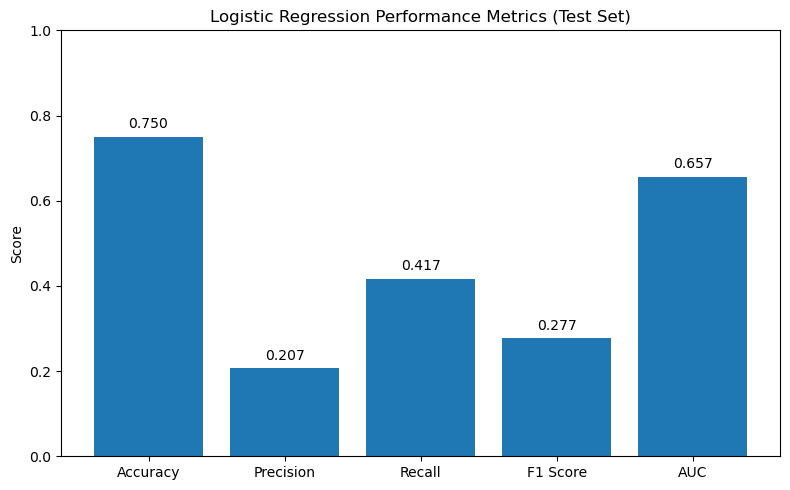

In [16]:
metrics = {
    'Accuracy': accuracy_score(y_test, final_predictions),
    'Precision': precision_score(y_test, final_predictions),
    'Recall': recall_score(y_test, final_predictions),
    'F1 Score': f1_score(y_test, final_predictions),
    'AUC': auc
}

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics.keys(), metrics.values())
plt.title('Logistic Regression Performance Metrics (Test Set)')
plt.ylabel('Score')
plt.ylim(0, 1)
for bar, value in zip(bars, metrics.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f'{value:.3f}', ha='center')
plt.tight_layout()
plt.show()

## Interpreting the Model
One big advantage of logistic regression is that it's easy to interpret. Each weight shows how a feature
changes the log-odds of readmission. A positive weight means higher risk, a negative weight means lower risk.
Since I scaled the numeric features, their weights can be compared directly.

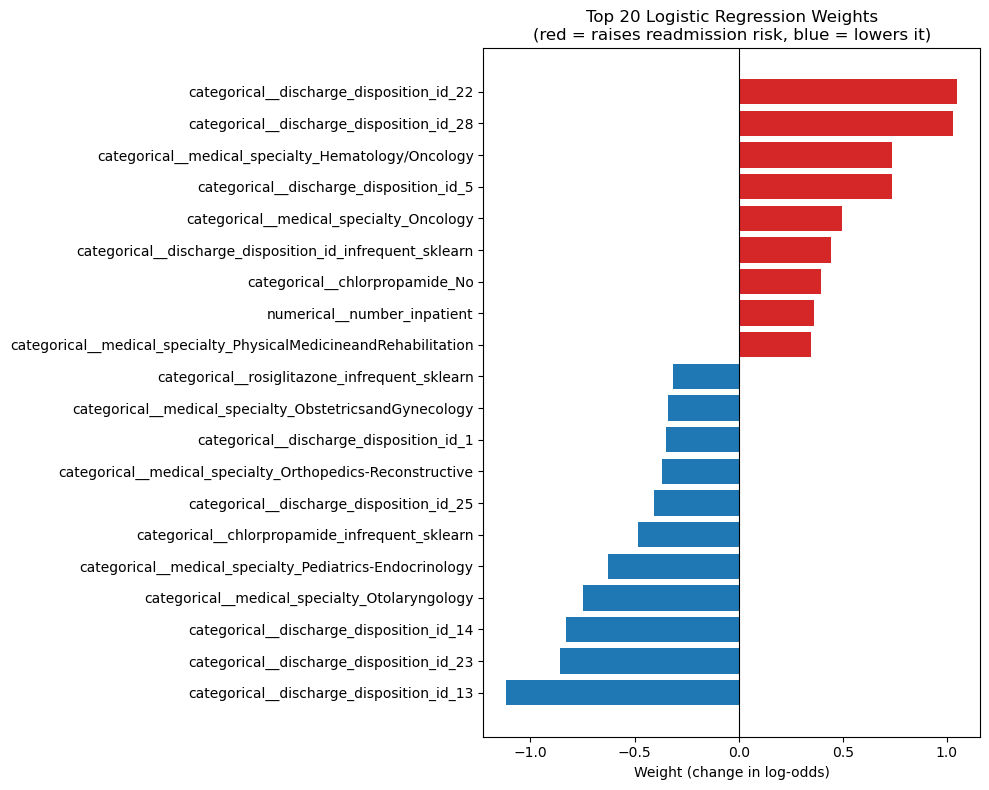

                                                         Feature  Weight
                        categorical__discharge_disposition_id_13  -1.118
                        categorical__discharge_disposition_id_22   1.050
                        categorical__discharge_disposition_id_28   1.031
                        categorical__discharge_disposition_id_23  -0.857
                        categorical__discharge_disposition_id_14  -0.830
                   categorical__medical_specialty_Otolaryngology  -0.747
              categorical__medical_specialty_Hematology/Oncology   0.738
                         categorical__discharge_disposition_id_5   0.734
         categorical__medical_specialty_Pediatrics-Endocrinology  -0.628
                         categorical__medical_specialty_Oncology   0.497
                  categorical__chlorpropamide_infrequent_sklearn  -0.484
        categorical__discharge_disposition_id_infrequent_sklearn   0.446
                        categorical__discharge_disp

In [17]:
lr = final_model.named_steps['classifier']
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()

weights_df = pd.DataFrame({'Feature': feature_names, 'Weight': lr.coef_[0]})
weights_df['abs'] = weights_df['Weight'].abs()
top = weights_df.sort_values('abs', ascending=False).head(20).sort_values('Weight')

plt.figure(figsize=(10, 8))
plt.barh(top['Feature'], top['Weight'],
         color=['tab:red' if w > 0 else 'tab:blue' for w in top['Weight']])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 20 Logistic Regression Weights\n(red = raises readmission risk, blue = lowers it)')
plt.xlabel('Weight (change in log-odds)')
plt.tight_layout()
plt.show()

print(weights_df.sort_values('abs', ascending=False).head(20)[['Feature', 'Weight']]
      .round(3).to_string(index=False))

## Results Summary

In [18]:
summary = pd.DataFrame([{
    'Model': 'Logistic Regression',
    'C': best_C,
    'Threshold': best_threshold,
    'Accuracy': accuracy_score(y_test, final_predictions),
    'Precision': precision_score(y_test, final_predictions),
    'Recall': recall_score(y_test, final_predictions),
    'F1': f1_score(y_test, final_predictions),
    'AUC': auc
}])
print(summary.round(4).to_string(index=False))
summary.to_csv('logistic_regression_results.csv', index=False)

              Model   C  Threshold  Accuracy  Precision  Recall     F1    AUC
Logistic Regression 0.1       0.55    0.7497     0.2071  0.4174 0.2769 0.6568


## Concluding Thoughts
* **Test results** (C = 0.1, threshold = 0.55): accuracy **0.750**, precision **0.207**, recall **0.417**,
  F1 **0.277**, AUC **0.657**. The model caught 962 of the 2,305 readmissions in the test set, missed 1,343,
  and gave 3,682 false alarms.
* **Stability:** 5-fold cross validation gave F1 = 0.272 +/- 0.001 and AUC = 0.665 +/- 0.003, so the
  results are consistent and don't depend on one particular split.
* **My version vs. scikit-learn:** my NumPy gradient-descent version got almost the same validation scores
  (F1 0.275, AUC 0.666) as scikit-learn (F1 0.278, AUC 0.669), which shows they really are the same model.
* **Regularization** barely mattered (validation F1 0.274-0.278 for C from 0.001 to 100). With ~60,000
  training rows and 170 features the model isn't overfitting. What limits it is how much information the
  features carry, not how much data we have.
* **Accuracy vs. the baseline:** always predicting "not readmitted" gets 0.885 accuracy but finds zero
  readmissions, so that accuracy doesn't mean much here. My model gives up some accuracy to catch about 42%
  of readmissions. The threshold controls this trade-off: a hospital that cares more about catching
  readmissions could lower it and accept more false alarms.
* **What drives readmission risk:** among the numeric features, the number of **inpatient visits in the
  previous year** has by far the biggest weight (+0.36 per standard deviation), followed by being on diabetes
  medication, the number of diagnoses and emergency visits. Where the patient goes after discharge matters
  a lot too. Patients sent to hospice (codes 13, 14) are much less likely to be readmitted, while patients
  sent to a rehab facility (22) or a psychiatric hospital (28) are more likely.
* **Overall:** predicting readmission within 30 days from discharge information alone is hard (AUC ~0.66).
  Logistic regression performs in the same range as our Random Forest (recall 0.34, precision 0.21), and it
  has the advantage of being easy to explain, since every weight shows how a feature affects the risk.